# Advección de cuatro armónicos: ¿qué cambia con 5000 pasos?

**Pregunta experimental.** En la corrida de 2000 pasos, PCA `k=6` y `k=8` quedaron lejos de la PINN base en algunas métricas. ¿Mejoran al darles más tiempo de optimización?

Se repite el mismo barrido con el mismo campo analítico y diez semillas, pero se extiende el entrenamiento a 5000 pasos. Se comparan métricas de prueba al final de cada presupuesto y la trayectoria de validación.

## Protocolo y comparación justa

- Mismos datos Fourier, semillas, particiones, puntos iniciales, arquitectura, tasa de aprendizaje y secuencias de minibatches del experimento de 2000 pasos.
- La corrida larga es una extensión del mismo prefijo: los 1000 checkpoints de validación hasta el paso 2000 coinciden exactamente entre ambas corridas.
- La validación se evalúa cada 100 pasos. El conjunto de prueba se evalúa al final de cada corrida; las métricas de prueba no se usan para modificar entrenamiento ni configuración.
- Se reportan error relativo L2, residuo PDE, defecto de periodicidad y tiempo total de pipeline. El tiempo de compilación queda excluido de las cifras de pipeline.

In [ ]:
from pathlib import Path
import csv, json, sys
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_2K = ROOT / "results/advection/base_vs_pca/fourier_rich_k_sweep_10_seeds_v1"
RUN_5K = ROOT / "results/advection/base_vs_pca/fourier_rich_k_sweep_10_seeds_5k_v1"
R2 = json.loads((RUN_2K / "summary.json").read_text(encoding="utf-8"))
R5 = json.loads((RUN_5K / "summary.json").read_text(encoding="utf-8"))
ORDER = ["PINN base", "PCA AD 99%", "PCA AD k=2", "PCA AD k=6", "PCA AD k=8"]
sys.path.insert(0, str(ROOT / "src"))
from pinn_pca.plotting import budget_grouped_metric_svg

BUDGET_SUMMARIES = {"2000 pasos": R2["summary"], "5000 pasos": R5["summary"]}
MODEL_LABELS = {"PINN base": "Base", "PCA AD 99%": "99% (k=4)", "PCA AD k=2": "k=2", "PCA AD k=6": "k=6", "PCA AD k=8": "k=8"}
budget_grouped_metric_svg(RUN_5K / "budget_test_relative_l2.svg", BUDGET_SUMMARIES, "test_relative_l2", "Error de prueba: 2000 vs. 5000 pasos", "Error relativo L2", MODEL_LABELS)
budget_grouped_metric_svg(RUN_5K / "budget_test_pde_residual_rms.svg", BUDGET_SUMMARIES, "test_pde_residual_rms", "Residuo de prueba: 2000 vs. 5000 pasos", "Residuo RMS PDE", MODEL_LABELS)


def html_table(headers, rows):
    head = "".join(f"<th>{h}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def stat(summary, name, metric, digits=4):
    v = summary["summary"][name][metric]
    return f"{v['mean']:.{digits}g} ± {v['std']:.{digits}g}"


## Resultados finales: 2000 frente a 5000 pasos

Cada métrica es media ± desviación estándar entre diez semillas. El conteo indica cuántas semillas mejoraron al pasar de 2000 a 5000 pasos.

In [1]:
rows = []
for name in ORDER:
    a, b = R2["summary"][name], R5["summary"][name]
    r2 = {r["seed"]: r for r in R2["runs"] if r["model"] == name}
    r5 = {r["seed"]: r for r in R5["runs"] if r["model"] == name}
    wins_l2 = sum(r5[s]["test_relative_l2"] < r2[s]["test_relative_l2"] for s in r2)
    wins_pde = sum(r5[s]["test_pde_residual_rms"] < r2[s]["test_pde_residual_rms"] for s in r2)
    k = "—" if b["k"] is None else f"{b['k']['mean']:.0f}"
    rows.append([name, k, stat(R2, name, "test_relative_l2"), stat(R5, name, "test_relative_l2"), f"{wins_l2}/10", stat(R2, name, "test_pde_residual_rms"), stat(R5, name, "test_pde_residual_rms"), f"{wins_pde}/10", stat(R5, name, "pipeline_seconds", 3)])
display(HTML(html_table(["Modelo", "k", "Error L2 2k", "Error L2 5k", "L2 mejora 5k vs 2k", "Residuo 2k", "Residuo 5k", "Residuo mejora", "Pipeline 5k (s)"], rows)))


Modelo,k,Error L2 2k,Error L2 5k,L2 mejora 5k vs 2k,Residuo 2k,Residuo 5k,Residuo mejora,Pipeline 5k (s)
PINN base,—,0.06016 ± 0.008801,0.04153 ± 0.007297,10/10,0.02283 ± 0.003118,0.02039 ± 0.002992,9/10,7.96 ± 0.228
PCA AD 99%,4,0.1743 ± 0.02442,0.1664 ± 0.01963,8/10,0.5796 ± 0.07295,0.5797 ± 0.07773,4/10,6.83 ± 0.3
PCA AD k=2,2,0.4782 ± 0.02262,0.4818 ± 0.03286,5/10,1.025 ± 0.1005,1.007 ± 0.08807,9/10,6.82 ± 0.253
PCA AD k=6,6,0.06858 ± 0.005838,0.02493 ± 0.007976,10/10,0.197 ± 0.04511,0.1399 ± 0.0309,10/10,6.88 ± 0.271
PCA AD k=8,8,0.1089 ± 0.01156,0.01256 ± 0.002239,10/10,0.07312 ± 0.01495,0.02639 ± 0.002821,10/10,6.83 ± 0.328


## Comparación visual del efecto del presupuesto

Las barras comparan los resultados finales en prueba de ambas corridas; las barras de error muestran la desviación estándar entre semillas.

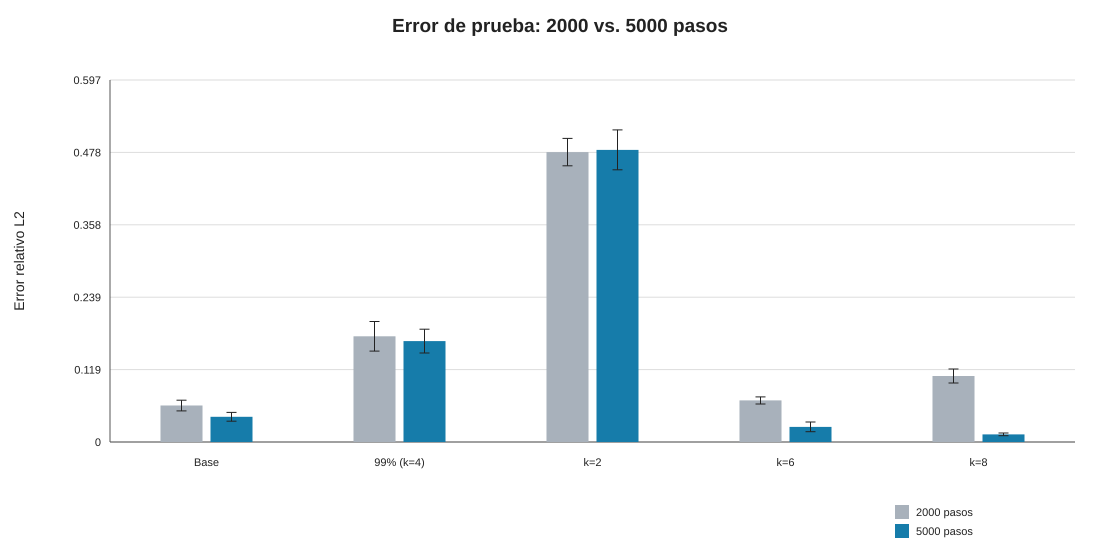

In [3]:
display(SVG(filename=str(RUN_5K / "budget_test_relative_l2.svg")))


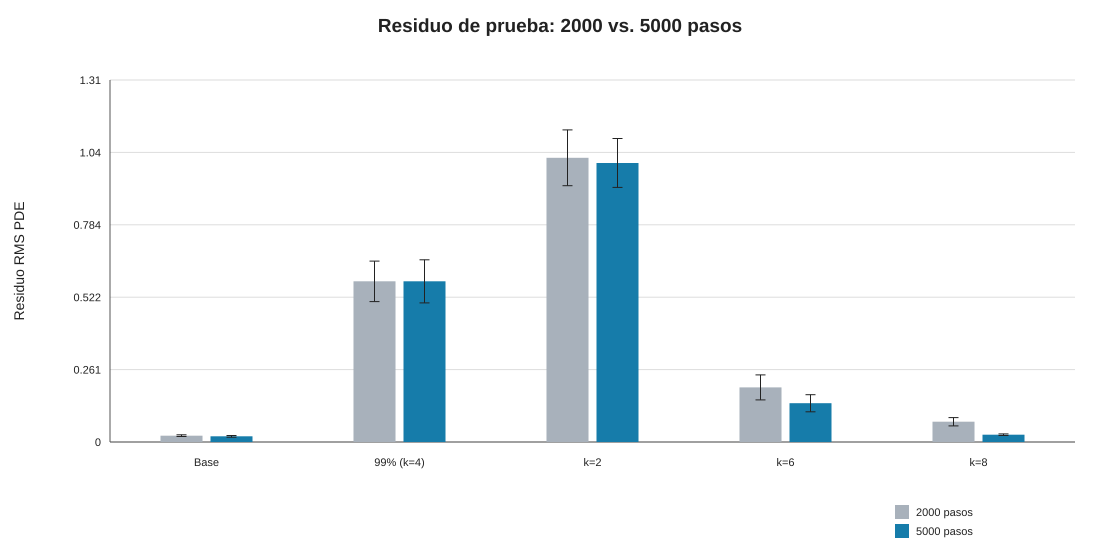

In [3]:
display(SVG(filename=str(RUN_5K / "budget_test_pde_residual_rms.svg")))


## Check de continuidad del entrenamiento

Para comprobar que el cambio de presupuesto no alteró el prefijo experimental, comparamos cada checkpoint de validación hasta 2000 pasos entre las dos corridas.

In [1]:
def load_validation(path):
    with (path / "validation_trajectories.csv").open(encoding="utf-8", newline="") as f:
        return {(r["model"], int(r["seed"]), int(r["step"])): float(r["validation_rmse"]) for r in csv.DictReader(f)}

v2, v5 = load_validation(RUN_2K), load_validation(RUN_5K)
common = [key for key in v2 if key in v5 and key[2] <= 2000]
max_gap = max(abs(v2[key] - v5[key]) for key in common)
print(f"Checkpoints comparables hasta 2000 pasos: {len(common)}")
print(f"Diferencia absoluta máxima de RMSE de validación: {max_gap:.1e}")


Checkpoints comparables hasta 2000 pasos: 1000. Diferencia absoluta máxima de RMSE de validación: 0.0e+00.

## Trayectoria de validación hasta 5000 pasos

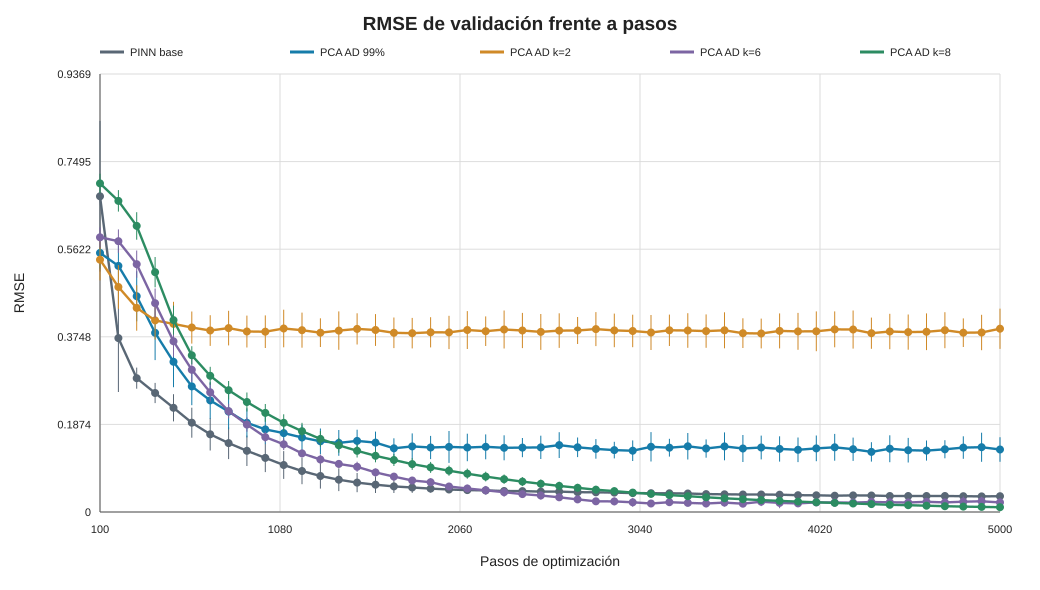

In [1]:
display(SVG(filename=str(RUN_5K / "validation_rmse_vs_steps.svg")))

## Métricas finales de la corrida larga

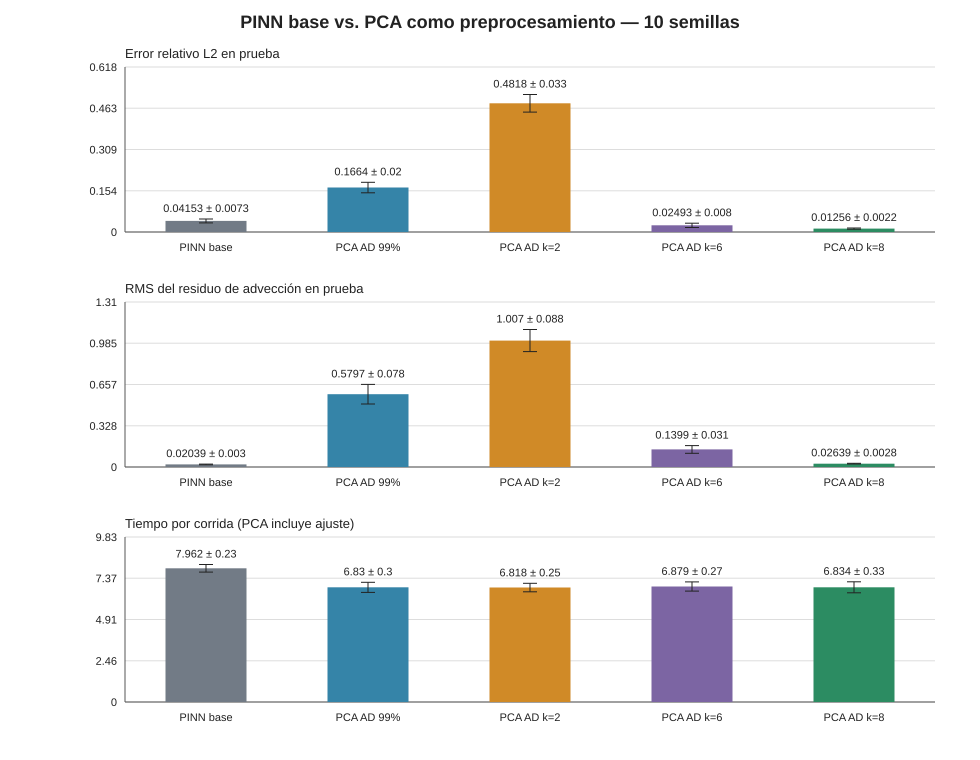

In [1]:
display(SVG(filename=str(RUN_5K / "comparison.svg")))

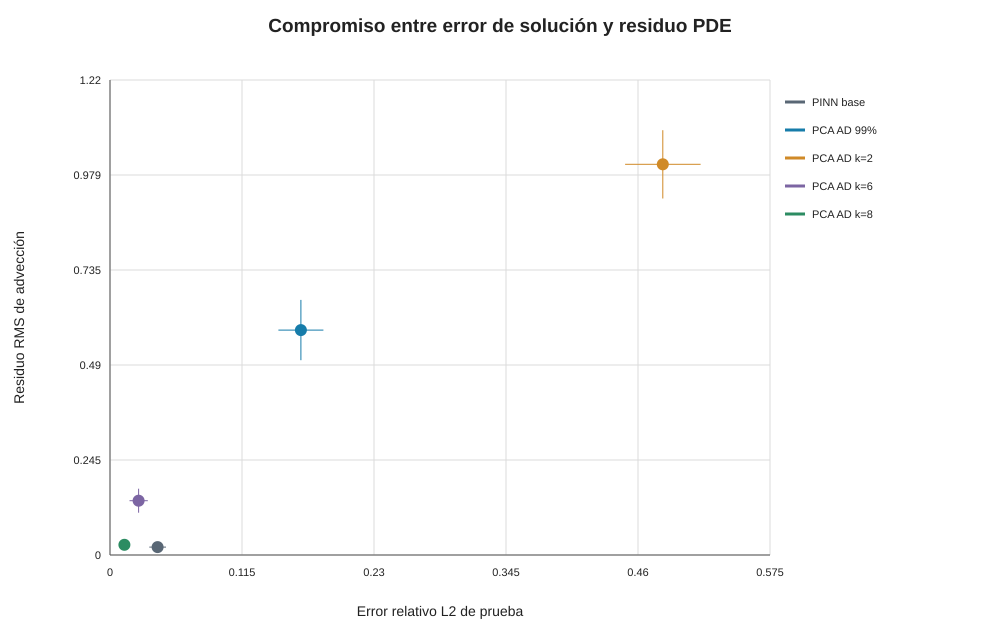

In [1]:
display(SVG(filename=str(RUN_5K / "error_residual_tradeoff.svg")))

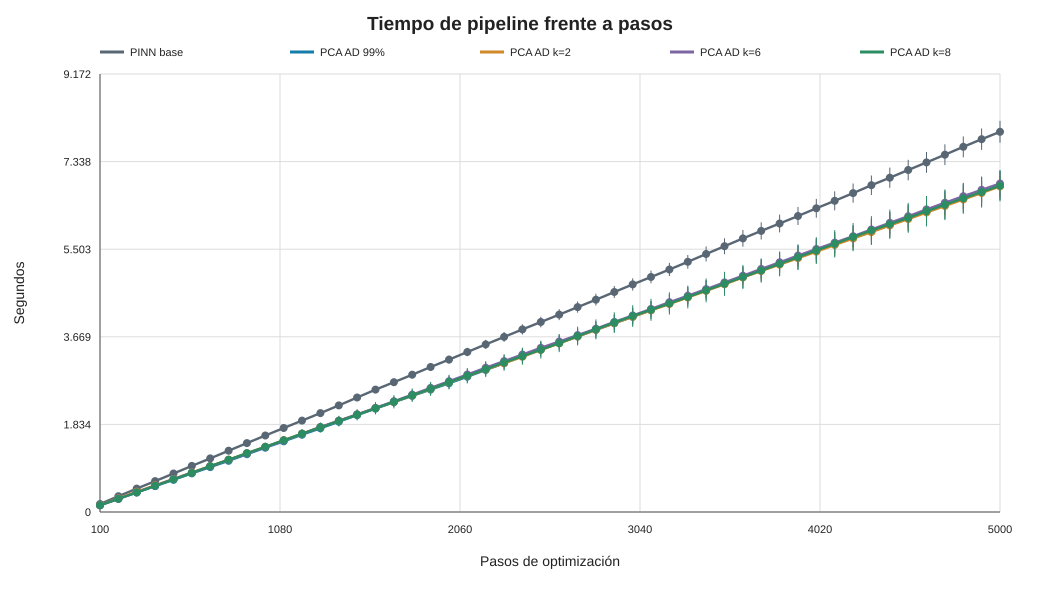

In [1]:
display(SVG(filename=str(RUN_5K / "pipeline_time_vs_steps.svg")))

## Diferencias pareadas de 5k frente a PINN base

In [1]:
rows = []
for name in ORDER:
    if name == "PINN base":
        rows.append([name, "referencia", "referencia"])
    else:
        m = R5["paired_differences_PCA_minus_base"][name]
        e, p = m["test_relative_l2"], m["test_pde_residual_rms"]
        rows.append([name, f"{e['PCA_minus_base_mean']:+.5f} ({e['PCA_better_count']}/10 mejores)", f"{p['PCA_minus_base_mean']:+.5f} ({p['PCA_better_count']}/10 mejores)"])
display(HTML(html_table(["Modelo 5k", "Δ error L2 vs base", "Δ residuo vs base"], rows)))


Modelo 5k,Δ error L2 vs base,Δ residuo vs base
PINN base,referencia,referencia
PCA AD 99%,+0.12487 (0/10 mejores),+0.55933 (0/10 mejores)
PCA AD k=2,+0.44031 (0/10 mejores),+0.98642 (0/10 mejores)
PCA AD k=6,-0.01660 (9/10 mejores),+0.11948 (0/10 mejores)
PCA AD k=8,-0.02897 (10/10 mejores),+0.00600 (2/10 mejores)


## Interpretación

- **El mayor presupuesto sí ayudó a ciertas variantes PCA.** `k=6` mejoró el error relativo L2 en las 10 semillas (de 0,0686 a 0,0249) y el residuo PDE también bajó. `k=8` mejoró ambas métricas en las 10 semillas: el error L2 pasó de 0,1089 a **0,0126** y el residuo de 0,0731 a **0,0264**.
- La PINN base también mejoró con más pasos: error L2 de 0,0602 a **0,0415** y residuo PDE de 0,0228 a **0,0204**. Al final, `k=8` superó a la base en error de solución en **10/10 semillas**, pero su residuo PDE siguió siendo algo mayor en promedio (0,0264 frente a 0,0204; menor solo en 2/10 semillas).
- La variante automática al 99% continuó eligiendo `k=4`; su error L2 solo pasó de 0,1744 a 0,1664 y su residuo PDE permaneció alrededor de 0,58. Así, aumentar el tiempo por sí solo no corrigió la representación de cuatro componentes.
- `k=2` tampoco mejoró su error de solución. Más pasos no compensan siempre una compresión demasiado agresiva.
- El pipeline de `k=8` tomó en promedio **6,83 s**, frente a **7,96 s** de la base. Esta diferencia es específica de la máquina y configuración usadas.

**Conclusión acotada:** parte de la brecha observada a 2000 pasos sí era de optimización para `k=6` y especialmente `k=8`. Con 5000 pasos, `k=8` logra menor error de solución que la PINN base, aunque la base conserva un residuo PDE algo menor. La regla de 99% seleccionó `k=4` y no identificó la variante que rindió mejor; ambos hallazgos son específicos de esta condición inicial y presupuesto.

## Reproducibilidad

- Configuración de 5000 pasos: `configs/advection_fourier_k_sweep_5k.json`
- Ejecutor: `scripts/run_advection_k_sweep.py`
- Resultados: `results/advection/base_vs_pca/fourier_rich_k_sweep_10_seeds_5k_v1/`

```powershell
.venv-jax-latest\Scripts\python.exe scripts\run_advection_k_sweep.py --config configs\advection_fourier_k_sweep_5k.json
```
